In [162]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


In [163]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [164]:
df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [165]:
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = pd.to_numeric(df['horsepower'])
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

print(df['horsepower'].isnull().sum())

0


In [166]:
X = df[['horsepower']]
y = df['mpg']

print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [167]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [168]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape)

(318, 3)


In [169]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

print(X_train_scaled.shape)

(318, 3)


In [170]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [171]:
n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print(weights)
print(bias)

[0. 0. 0.]
0.0


In [172]:
learning_rate = 0.01
epochs = 1000

In [173]:
X_train_values = X_train_scaled
y_train_values = y_train.to_numpy()

n = len(y_train_values)
loss_history = []

In [174]:
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

m_weights = np.zeros(n_features)
v_weights = np.zeros(n_features)

m_bias = 0.0
v_bias = 0.0

In [184]:
for epoch in range(epochs):
    t = epoch + 1

    # Calculate predictions and gradients
    y_pred = X_train_values @ weights + bias
    errors = y_pred - y_train_values

    gradients = (2 / n) * (X_train_values.T @ errors)
    bias_gradient = (2 / n) * np.sum(errors)

    # Update first moment
    m_weights = beta1 * m_weights + (1 - beta1) * gradients
    m_bias = beta1 * m_bias + (1 - beta1) * bias_gradient

    # Update second moment
    v_weights = beta2 * v_weights + (1 - beta2) * (gradients ** 2)
    v_bias = beta2 * v_bias + (1 - beta2) * (bias_gradient ** 2)

    # Bias correction
    m_weights_corrected = m_weights / (1 - beta1 ** t)
    m_bias_corrected = m_bias / (1 - beta1 ** t)

    v_weights_corrected = v_weights / (1 - beta2 ** t)
    v_bias_corrected = v_bias / (1 - beta2 ** t)

    # Update weights and bias
    weights = weights - learning_rate * m_weights_corrected / (
        np.sqrt(v_weights_corrected) + epsilon
    )

    bias = bias - learning_rate * m_bias_corrected / (
        np.sqrt(v_bias_corrected) + epsilon
    )

    # Calculate loss
    y_pred = X_train_values @ weights + bias
    loss = mse(y_train_values, y_pred)
    loss_history.append(loss)

    if epoch % 100 == 0:
        print("Epoch:", epoch, "Loss:", loss)

Epoch: 0 Loss: 613.0513079599358
Epoch: 100 Loss: 233.80362027199882
Epoch: 200 Loss: 85.51429106127068
Epoch: 300 Loss: 37.7517826145526
Epoch: 400 Loss: 26.097153989736388
Epoch: 500 Loss: 23.5332618941357
Epoch: 600 Loss: 22.704043500949016
Epoch: 700 Loss: 22.26053235189893
Epoch: 800 Loss: 21.993165293189225
Epoch: 900 Loss: 21.83823879921615


In [176]:
learning_rate = 0.1

weights = np.zeros(n_features)
bias = 0.0

m_weights = np.zeros(n_features)
v_weights = np.zeros(n_features)

m_bias = 0.0
v_bias = 0.0

loss_history = []

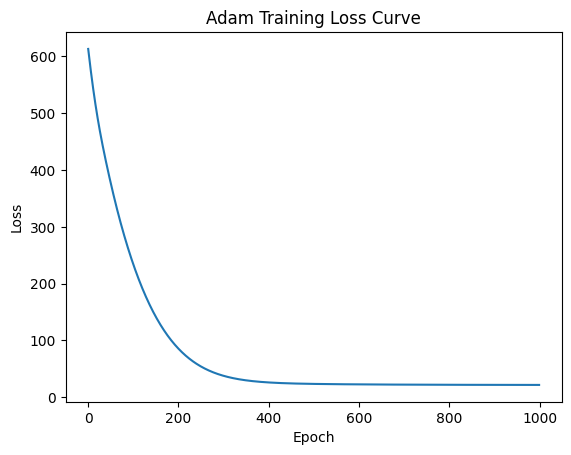

In [185]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam Training Loss Curve")
plt.show()

In [195]:
y_test_pred = X_test_scaled @ weights + bias

test_mse = mse(y_test.to_numpy(), y_test_pred)
test_rmse = np.sqrt(test_mse)

print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse) 

Test MSE: 13.720280063066877
Test RMSE: 3.704089640258032


In [193]:
print("Weights:", weights)
print("Bias:", bias)
print("First 5 predictions:", y_test_pred[:5])

Weights: [  0.         -15.66295941   9.81602802]
Bias: 23.60807014677349
First 5 predictions: [0. 0. 0. 0. 0.]


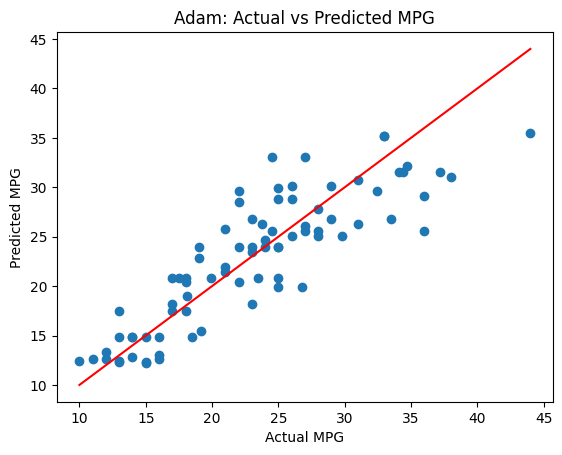

In [196]:
plt.scatter(y_test, y_test_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Adam: Actual vs Predicted MPG")
plt.show()

In [181]:
print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(y_test_pred[:10])

Actual values:
[33. 28. 19. 13. 14. 27. 24. 13. 17. 21.]
Predicted values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


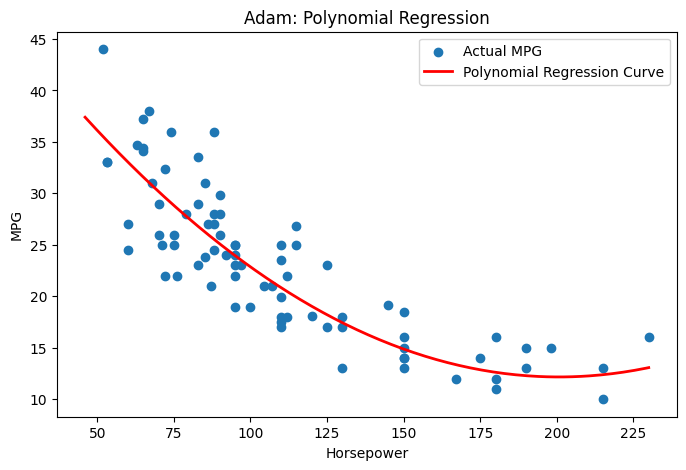

In [191]:
horsepower_range = np.linspace(
    X['horsepower'].min(),
    X['horsepower'].max(),
    200
).reshape(-1, 1)

horsepower_grid = pd.DataFrame({
    'horsepower': horsepower_range.flatten()
})

horsepower_poly = poly.transform(horsepower_grid)
horsepower_scaled = scaler.transform(horsepower_poly)

predicted_curve = horsepower_scaled @ weights + bias

plt.figure(figsize=(8, 5))

plt.scatter(X_test['horsepower'], y_test, label='Actual MPG')

plt.plot(
    horsepower_range,
    predicted_curve,
    color='red',
    linewidth=2,
    label='Polynomial Regression Curve'
)

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Adam: Polynomial Regression')
plt.legend()
plt.show()